# Building a Network Topology

In the previous page, we saw how to load a network whose topology is already defined. In this case, each edge is associated with a source node and a target node, whose identifiers are stored together with the edge geometry.

However, network datasets do not always provide this connectivity information. In some cases, they contain only the geometries of the edges. The topology must then be reconstructed from these geometries.

Tracklib provides a way to reconstruct the topology by comparing the extremities of the edges. Two edge extremities are considered to belong to the same node when they are sufficiently close according to a distance threshold. The choice of this threshold is important: a threshold that is too small may leave some connections undetected, while a threshold that is too large may create connections that do not actually exist.

The <b>Topology builder</b> provides static methods for constructing topological network structures from raw network data. See the doc [Topology Builder](../api/util/topology) page for the API documentation.

For example, the create_topology method reads the edge geometries from an input text file and writes the resulting topological network to a new file using the format expected by the network loader described in the previous page.

The <i>create_topology</i> method can be used as follows:

<div class="alert alert-block alert-info" style="padding:1em">

```python
tkl.Topology.create_topology(
    input_file: str,
    srid: str,
    output_file: str,
    tbp: float = 1e-6
) -> Void
```

</div>

The method requires three parameters:

<ul>
    <li><strong>input_file (str)</strong>: Path to a text file containing a list of line or multiline geometries in WKT format.</li> 
    <li><strong>srid (str) = '2154'</strong>: Coordinate reference system of the geometry vertices.</li> 
    <li><strong>output_file (str)</strong>: Path to the output file where the resulting topological network will be stored.</li> 
</ul>

The optional <strong>tbp</strong> parameter controls the distance threshold used during topology reconstruction:

<ul> <li><strong>tbp (float)</strong>: Maximum distance between two edge extremities for them to be considered part of the same node. The default value is <code>1e-6</code>.</li> </ul>



## As usual, let’s start by defining our environment

The first task is <b>only</b> useful for the online notebook and import the local tracklib code source. It’s not necessary if tracklib is installed from PyPI.

In [1]:
import os
import sys

# Import de tracklib
module_path = os.path.abspath(os.path.join('../../../../'))
if module_path not in sys.path:
    sys.path.append(module_path)

The following two imports are necessary for the tutorial:

In [2]:
import matplotlib.pyplot as plt

# Import tracklib library
import tracklib as tkl

Code running in a no shapely environment


## Creating the topology

We first provide the path to the input network and the path where the topological network will be written.


The input file contains one edge geometry per line, expressed as a WKT `LINESTRING`. For example, the first three lines of the input file are:

```text
LINESTRING (996820.0467970388 6542998.535049813, 996816.0977736968 6542995.960682608)
LINESTRING (996812.2508521522 6542988.409713146, 996811.1656191207 6542994.186409845)
LINESTRING (996811.921331907 6542994.342233916, 996811.1656191207 6542994.186409845)
```

The second and third edges share the same extremity. The first edge has an extremity that is very close to this location. Depending on the value of `tbp`, these edge extremities can therefore be associated with the same topological node.

In [3]:
input_file  = r'/home/md_vandamme/res.csv'
output_file = r'/home/md_vandamme/res_topology.csv'

tkl.Topology.create_topology(input_file, '2154', output_file)

## Reading the resulting network

The resulting file follows the network format described in the previous tutorial. We can therefore load it using `NetworkReader`.

In [4]:
fmt = tkl.NetworkFormat({
       "pos_edge_id": 0,
       "pos_source": 1,
       "pos_target": 2,
       "pos_wkt": 3,
       "srid": "ENU",
       "separator": ",",
       "header": 1})

network = tkl.NetworkReader.readFromFile(output_file, fmt, verbose=False)

## Visualizing the topology

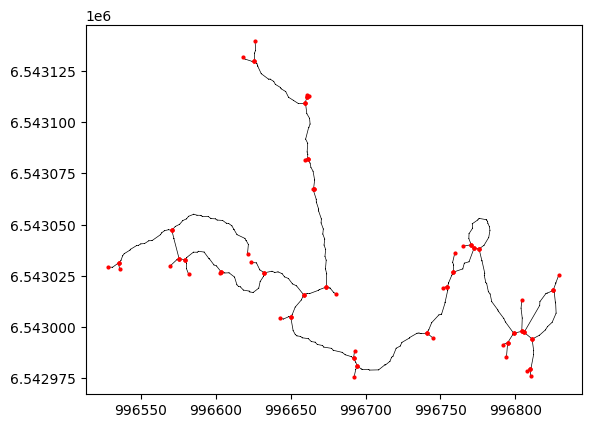

In [5]:
network.plot('k-', 'ro', 'g-', 'r-', 0.5, plt)